<a href="https://colab.research.google.com/github/Prateek0325/Machine-Learning-Projects/blob/main/Titanic_Passenger_Survival.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Titanic Passenger Survival Prediction**
# **Problem Statement**
During the Titanic disaster, passenger survival was influenced by factors such as age, gender,
and passenger class.

The objective of this project is to build a **binary classification machine learning model** to
predict whether a passenger survived (Yes/No) using historical passenger data and to identify
the most important factors affecting surviva

# **Objectives of the Project**
* Understand passenger survival patterns

* Perform basic data preprocessing

* Conduct **minimal but meaningful EDA**

* Build binary classification models

* Evaluate model performance

* Identify key survival-influencing features

**Load the datase**

In [ ]:
#Uploading file
from google.colab import files
upload = files.upload()

Saving train.csv to train (1).csv


In [ ]:
#Loading/Reading the Dataset

import pandas as pd
df = pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
#importing libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier

# **Exploratory Data Analysis (EDA) - Minimal Graphs**
**Graph 1:** **Survival Count Plot**

**Purpose:**
* Understand class distribution
* Confirm binary classification nature

**Graph:**
* Bar chart: Survived vs Not Survived

/tmp/ipython-input-1759349658.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Survived", data=df, palette="Set2")


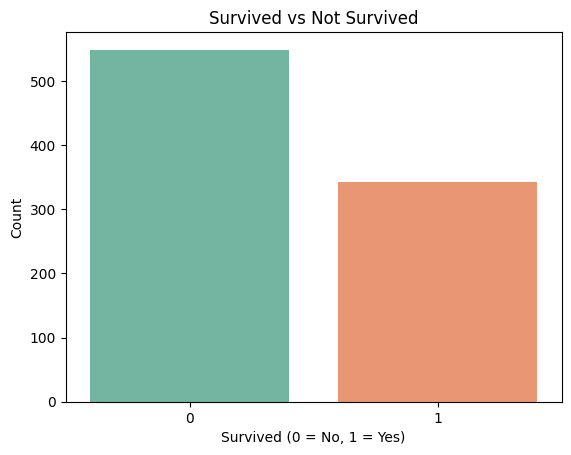

In [ ]:
sns.countplot(x="Survived", data=df, palette="Set2")
plt.title("Survived vs Not Survived")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

**Graph 2**: **Survival by Gender**

**Purpose**:
*  Analyze impact of gender on survival

**Graph**:

· Analyze impact of gender on survival

· Bar chart

· **X-axis**: *Sex*

· **Hue**: *Survived*

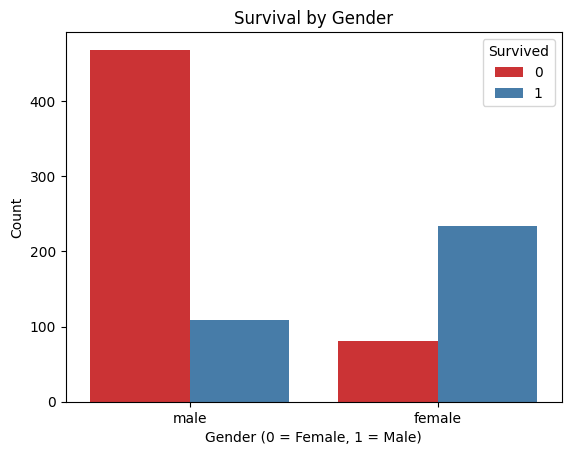

In [ ]:
sns.countplot(x="Sex", hue="Survived", data=df, palette="Set1")
plt.title("Survival by Gender")
plt.xlabel("Gender (0 = Female, 1 = Male)")
plt.ylabel("Count")
plt.show()

**Graph 3: Survival by Passenger Class**

**Purpose:**
* Understand effect of socio-economic status

**Graph 3:**

· Bar chart

· **X-axis:** *Pclass*

· **Hue:** *Survived*

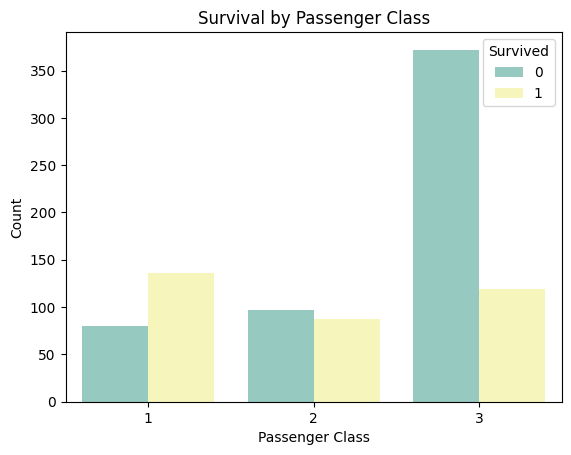

In [ ]:
sns.countplot(x="Pclass", hue="Survived", data=df, palette="Set3")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

**Graph 4: Fare vs Survival**

**Purpose:**

* Analyze relationship between ticket fare and survival

**Graph:**

* Box plot
* **X-axis:** *Survived*
* **Y-axis:** *Fare*


/tmp/ipython-input-1517249545.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Survived", y="Fare", data=df, palette="coolwarm")


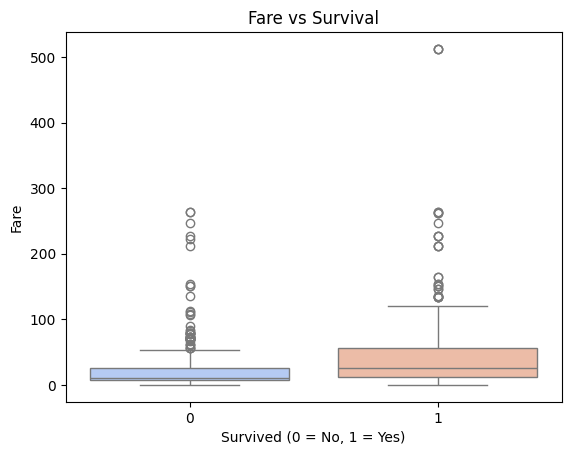

In [ ]:
sns.boxplot(x="Survived", y="Fare", data=df, palette="coolwarm")
plt.title("Fare vs Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")
plt.show()

# **Machine Learning Workflow**

**Hndle missing values**

In [ ]:
#Checking missing values
df.isnull().sum()

NameError: name 'df' is not defined

In [ ]:
#Dropping high missing value column
df.drop('Cabin', axis=1, inplace=True)

In [ ]:
#Relevent columns
cols = ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
df = df[cols]

In [ ]:
#Filling numerical Data
df['Age'] = df['Age'].fillna(df['Age'].median())

#Filling Catogorical Data
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode())

df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,2


**Encoding Categorical Variables**

In [ ]:
#binary Encoding
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})

#Label Encoding
le = LabelEncoder()
df['Embarked'] = le.fit_transform(df['Embarked'])



*   Feature and Traget Value



In [ ]:
x = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
y = df['Survived']



**Scaling Numerical Features**




In [ ]:
scaler = StandardScaler()
numeric_cols = ['Age', 'Fare']
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])



**Train-Test Split**




In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

**Training Logistic Regression Model**




In [ ]:
model_lg = LogisticRegression()
model_lg.fit(x_train, y_train)

y_pred_lg = model_lg.predict(x_test)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lg))
print("Classification Report:\n", classification_report(y_test, y_pred_lg))

Logistic Regression Accuracy: 0.8100558659217877
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Training Decicsion Tree model**




In [ ]:
model_dt = DecisionTreeClassifier(criterion='gini', max_depth=3)
model_dt.fit(x_train, y_train)

y_pred_dt = model_dt.predict(x_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print(print("Classification Report:\n", classification_report(y_test, y_pred_dt)))

Decision Tree Accuracy: 0.7988826815642458
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.88      0.84       105
           1       0.80      0.69      0.74        74

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

None


**Train Random Forest Model**




In [ ]:
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_rf.fit(x_train, y_train)
y_pred_rf = model_rf.predict(x_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.8212290502793296
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179





**Confusion Matrix**




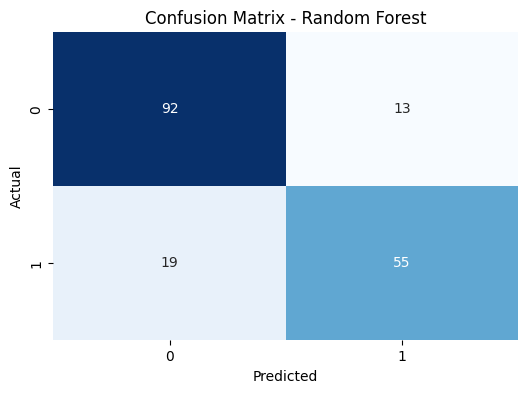

In [ ]:
cm = confusion_matrix(y_test, y_pred_rf)

# Ploting confusion matrix as heatmap
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# **Identifying Survival-Influencing Factors**
**Graph 6:**

Feature Importance (Random Forest)

**Purpose:**

* Identify most influential survival factors

**Graph:**

* Bar chart of feature importance

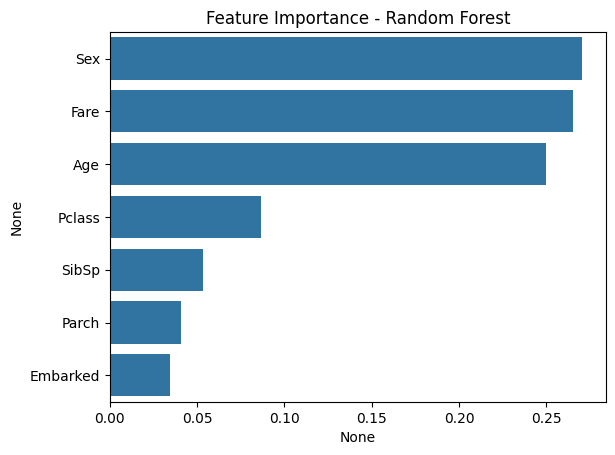

In [ ]:
feature_importance = pd.Series(
    model_rf.feature_importances_, index = x.columns
).sort_values(ascending = False)

sns.barplot(x=feature_importance, y=feature_importance.index)
plt.title("Feature Importance - Random Forest")
plt.show()